# 04 — ML ile Yolculuk Süresi Tahmini (Öğrenci 4)

NYC Yellow Taxi 2026 Ocak–Mayıs temiz verisi üzerinde yolculuk süresi (`trip_duration_min`) tahmini için
ölçeklenebilir bir PySpark MLlib pipeline'ı kuruyoruz ve scikit-learn ile kıyaslama yapıyoruz.

**Araştırma sorusu:** Veri büyüdükçe klasik yaklaşım (scikit-learn) ne zaman yetersiz kalıyor?

| Kaynak | Detay |
|---|---|
| Veri | `data/clean` — 17.210.961 kayıt, Parquet (snappy), partition: `pickup_year/pickup_month` |
| Hedef | `trip_duration_min` ∈ (1, 180] dk |
| Modeller | `LinearRegression` (baseline), `GBTRegressor(maxIter=15, maxDepth=5)` |
| Ölçek | 100K, 1M, 5M kayıt |
| Kıyaslama | scikit-learn `Ridge` ve `HistGradientBoostingRegressor` (ayrı subprocess) |

## 0. Ortam ve Import

In [1]:
import sys
from pathlib import Path

# Proje kökünü sys.path'e ekle
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Proje kökü: {PROJECT_ROOT}")
print(f"Python: {sys.version}")

Proje kökü: C:\Users\pc\Desktop\BVA_Project-main
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [2]:
import time
import psutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.spark_session import get_spark
from src.config import CLEAN_DIR, RESULTS_DIR, FIGURES_DIR
from src.ml_duration import (
    SAMPLE_SIZES, SAMPLE_LABELS, TARGET_COL,
    NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    _build_pipeline, _sample_data, _evaluate, _ram_mb,
    run_spark_experiments, run_sklearn_comparison,
    save_results, save_feature_importance, get_predictions_sample, make_plots
)

sns.set_theme(style="whitegrid", palette="muted")
print("Import başarılı ✓")

Import başarılı ✓


## 1. Spark Oturumu ve Veri Yükleme

In [3]:
# Spark oturumu — her zaman get_spark() ile açılır (kural: kendi SparkSession.builder yazma)
spark = get_spark(app_name="s4-ml-notebook")
print(f"Spark {spark.version} hazır")

Spark 3.5.9 hazır


In [4]:
# Temiz veri — Windows yollarını str() ile ver (Hadoop %20 bug'ından kaçın)
df_clean = spark.read.parquet(str(CLEAN_DIR))
total_rows = df_clean.count()
print(f"Toplam kayıt: {total_rows:,}")
assert total_rows == 17_210_961, f"Beklenen 17.210.961, gerçek: {total_rows}"

Toplam kayıt: 17,210,961


In [5]:
# Şema ve ilk birkaç satır
df_clean.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- avg_speed_mph: double 

In [6]:
# Hedef değişken dağılımı (Flex Fare dahil)
df_clean.select(TARGET_COL).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show()

+-------+------------------+
|summary| trip_duration_min|
+-------+------------------+
|  count|          17210961|
|   mean|16.611121617012905|
| stddev|12.083098840118646|
|    min|1.0166666666666666|
|    25%|               8.4|
|    50%|              13.6|
|    75%|21.183333333333334|
|    max|179.98333333333332|
+-------+------------------+



In [7]:
# Flex Fare kayıt oranı
flex_count = df_clean.filter("is_flex_fare = true").count()
print(f"Flex Fare kayıtları: {flex_count:,} ({100*flex_count/total_rows:.1f}%)")
print("NOT: Bu kayıtlarda passenger_count, RatecodeID vb. kasıtlı null — dropna() kullanılmadı")

Flex Fare kayıtları: 4,380,672 (25.5%)
NOT: Bu kayıtlarda passenger_count, RatecodeID vb. kasıtlı null — dropna() kullanılmadı


## 2. Feature Seçimi Gerekçesi

### Data Leakage'dan Kaçınma

| Kolon | Neden Dışlandı |
|---|---|
| `fare_amount`, `total_amount` | Yolculuk bittikten sonra hesaplanır; süreyle korelasyon yüksek (~0.8) ama gerçek zamanlı tahminde bilinmez |
| `tip_amount` | Yolcunun sonradan verdiği bahşiş — gelecekte bilinmez |
| `tpep_dropoff_datetime` | Hedef değişkenden türetiliyor — doğrudan leakage |

### Flex Fare Null Kolonları

| Kolon | Neden Dışlandı |
|---|---|
| `passenger_count` | 4.812.280 Flex Fare kaydında kasıtlı null |
| `RatecodeID` | Aynı nedenle null; Flex Fare'de taksimetre doldurmaz |
| `congestion_surcharge`, `Airport_fee` | Flex Fare'de null |
| `store_and_fwd_flag` | Kategorik, Flex Fare'de null, ML'de az bilgi içeriyor |

In [8]:
# Feature setimiz
print("Sayısal özellikler:", NUMERIC_FEATURES)
print("Kategorik özellikler:", CATEGORICAL_FEATURES)
print("Hedef:", TARGET_COL)

Sayısal özellikler: ['trip_distance', 'pickup_hour', 'pickup_dow', 'extra', 'mta_tax', 'tolls_amount', 'improvement_surcharge', 'cbd_congestion_fee']
Kategorik özellikler: ['PULocationID', 'DOLocationID']
Hedef: trip_duration_min


## 3. PySpark ML Pipeline — Mimarisi

In [9]:
# Pipeline stage'lerini listele
lr_pipeline = _build_pipeline("lr")
gbt_pipeline = _build_pipeline("gbt")

print("LinearRegression Pipeline Aşamaları:")
for i, s in enumerate(lr_pipeline.getStages()):
    print(f"  {i+1}. {type(s).__name__}")

print("\nGBTRegressor Pipeline Aşamaları:")
for i, s in enumerate(gbt_pipeline.getStages()):
    print(f"  {i+1}. {type(s).__name__}")

LinearRegression Pipeline Aşamaları:
  1. StringIndexer
  2. OneHotEncoder
  3. StringIndexer
  4. OneHotEncoder
  5. VectorAssembler
  6. LinearRegression

GBTRegressor Pipeline Aşamaları:
  1. StringIndexer
  2. OneHotEncoder
  3. StringIndexer
  4. OneHotEncoder
  5. VectorAssembler
  6. GBTRegressor


## 4. Küçük Örneklemde Hızlı Doğrulama (10K)

In [10]:
# 10K kayıt üzerinde pipeline'ı test et
needed_cols = [TARGET_COL] + NUMERIC_FEATURES + CATEGORICAL_FEATURES
df_sel = df_clean.select(needed_cols).filter(
    df_clean[TARGET_COL].isNotNull() & (df_clean[TARGET_COL] > 0)
)

df_10k = _sample_data(df_sel, 10_000)
train_10k, test_10k = df_10k.randomSplit([0.8, 0.2], seed=42)

print("=== LinearRegression (10K) ===")
t0 = time.perf_counter()
lr_model = _build_pipeline("lr").fit(train_10k)
lr_preds = lr_model.transform(test_10k)
lr_metrics = _evaluate(lr_preds)
print(f"  RMSE: {lr_metrics['rmse']:.3f} dk, MAE: {lr_metrics['mae']:.3f} dk, R²: {lr_metrics['r2']:.4f}")
print(f"  Süre: {time.perf_counter()-t0:.1f}s")

print("\n=== GBTRegressor (10K) ===")
t0 = time.perf_counter()
gbt_model = _build_pipeline("gbt").fit(train_10k)
gbt_preds = gbt_model.transform(test_10k)
gbt_metrics = _evaluate(gbt_preds)
print(f"  RMSE: {gbt_metrics['rmse']:.3f} dk, MAE: {gbt_metrics['mae']:.3f} dk, R²: {gbt_metrics['r2']:.4f}")
print(f"  Süre: {time.perf_counter()-t0:.1f}s")

=== LinearRegression (10K) ===


  RMSE: 7.340 dk, MAE: 4.992 dk, R²: 0.6243
  Süre: 8.2s

=== GBTRegressor (10K) ===


  RMSE: 6.475 dk, MAE: 4.247 dk, R²: 0.7076
  Süre: 9.2s


## 5. Tam Ölçeklenebilirlik Deneyi (100K / 1M / 5M)

In [11]:
# PySpark deneyleri — kayıtlı sonuç varsa doğrudan yükle (5M GBT ~22 dk sürer)
spark_csv = RESULTS_DIR / "s4_spark_results.csv"
if spark_csv.exists():
    spark_df = pd.read_csv(spark_csv)
    spark_results = spark_df.to_dict(orient="records")
    print(f"Kayıtlı PySpark sonuçları yüklendi ({len(spark_df)} satır): {spark_csv}")
else:
    print("PySpark deneyleri başlıyor...")
    spark_results = run_spark_experiments(spark, df_clean)
    spark_df = pd.DataFrame(spark_results)

spark_df

Kayıtlı PySpark sonuçları yüklendi (6 satır): C:\Users\pc\Desktop\BVA_Project-main\reports\results\s4_spark_results.csv


,framework,model,size_label,size_n,rmse,mae,r2,train_time_s,predict_time_s,peak_ram_mb
0,PySpark,LinearRegression,100K,100000,7.1924,4.9083,0.6467,4.04,0.50,72.1
1,PySpark,GBTRegressor,100K,100000,6.2407,4.1061,0.7340,10.74,0.34,72.3
2,PySpark,LinearRegression,1M,1000000,7.1871,4.9370,0.6487,5.19,2.04,72.4
3,PySpark,GBTRegressor,1M,1000000,6.2729,4.1399,0.7324,61.93,0.86,72.4
4,PySpark,LinearRegression,5M,5000000,7.1933,4.9254,0.6459,18.10,7.84,72.3
5,PySpark,GBTRegressor,5M,5000000,6.2842,4.1415,0.7297,1303.91,4.25,72.4


In [12]:
# scikit-learn kıyaslaması — kayıtlı sonuç varsa doğrudan yükle
sklearn_csv = RESULTS_DIR / "s4_sklearn_comparison.csv"
if sklearn_csv.exists():
    sklearn_df = pd.read_csv(sklearn_csv)
    sklearn_rows = sklearn_df.to_dict(orient="records")
    print(f"Kayıtlı scikit-learn sonuçları yüklendi ({len(sklearn_df)} satır): {sklearn_csv}")
else:
    print("scikit-learn kıyaslaması başlıyor...")
    sklearn_rows = run_sklearn_comparison(str(CLEAN_DIR))
    sklearn_df = pd.DataFrame(sklearn_rows)

sklearn_df

Kayıtlı scikit-learn sonuçları yüklendi (6 satır): C:\Users\pc\Desktop\BVA_Project-main\reports\results\s4_sklearn_comparison.csv


,framework,model,size_n,rmse,mae,r2,train_time_s,predict_time_s,peak_ram_mb,error
0,scikit-learn,Ridge,100000,7.3340,5.1205,0.6260,0.01,0.0004,2441.7,NaN
1,scikit-learn,HistGradientBoosting,100000,5.9556,3.9040,0.7534,0.25,0.0292,2443.3,NaN
2,scikit-learn,Ridge,1000000,7.4000,5.1281,0.6276,0.04,0.0042,2540.7,NaN
3,scikit-learn,HistGradientBoosting,1000000,5.9275,3.8755,0.7611,1.93,0.3199,2545.9,NaN
4,scikit-learn,Ridge,5000000,7.4119,5.1396,0.6261,0.23,0.0136,3124.6,NaN
5,scikit-learn,HistGradientBoosting,5000000,5.9263,3.8849,0.7610,12.16,1.5821,3132.2,NaN


In [13]:
# Sonuçları kaydet (zaten mevcutsa doğrula)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
if not (RESULTS_DIR / "s4_comparison.csv").exists():
    save_results(spark_results, sklearn_rows)
print("CSV sonuçları hazır ✓")

CSV sonuçları hazır ✓


## 6. Karşılaştırma Tablosu

In [14]:
# Birleşik karşılaştırma
comp_df = pd.read_csv(RESULTS_DIR / "s4_comparison.csv")
print("=== Karşılaştırma Tablosu ===")
print(comp_df.to_string(index=False))

=== Karşılaştırma Tablosu ===
   framework                model size_label  size_n   rmse    mae     r2  train_time_s  predict_time_s  peak_ram_mb  error
     PySpark     LinearRegression       100K  100000 7.1924 4.9083 0.6467          4.04          0.5000         72.1    NaN
     PySpark         GBTRegressor       100K  100000 6.2407 4.1061 0.7340         10.74          0.3400         72.3    NaN
     PySpark     LinearRegression         1M 1000000 7.1871 4.9370 0.6487          5.19          2.0400         72.4    NaN
     PySpark         GBTRegressor         1M 1000000 6.2729 4.1399 0.7324         61.93          0.8600         72.4    NaN
     PySpark     LinearRegression         5M 5000000 7.1933 4.9254 0.6459         18.10          7.8400         72.3    NaN
     PySpark         GBTRegressor         5M 5000000 6.2842 4.1415 0.7297       1303.91          4.2500         72.4    NaN
scikit-learn                Ridge       100K  100000 7.3340 5.1205 0.6260          0.01          0.000

## 7. Feature Önemi

In [15]:
imp_path = RESULTS_DIR / "s4_feature_importance.csv"
if imp_path.exists():
    imp_df = pd.read_csv(imp_path)
    importance_dict = dict(zip(imp_df["feature"], imp_df["importance"]))
    print(f"Kayıtlı feature importance yüklendi: {imp_path}")
else:
    importance_dict = save_feature_importance(spark, df_clean, imp_path)

# İlk 10 özellik
top10 = list(importance_dict.items())[:10]
print("Feature Önemi (İlk 10):")
for feat, imp in top10:
    bar = "█" * int(imp * 100)
    print(f"  {feat:<35} {imp:.4f} {bar}")

Kayıtlı feature importance yüklendi: C:\Users\pc\Desktop\BVA_Project-main\reports\results\s4_feature_importance.csv
Feature Önemi (İlk 10):
  trip_distance                       0.6201 ██████████████████████████████████████████████████████████████
  pickup_hour                         0.1444 ██████████████
  pickup_dow                          0.1005 ██████████
  cbd_congestion_fee                  0.0273 ██
  DOLocationID_40                     0.0146 █
  extra                               0.0114 █
  DOLocationID_5                      0.0108 █
  improvement_surcharge               0.0100 █
  DOLocationID_73                     0.0093 
  DOLocationID_45                     0.0080 


## 8. Görselleştirmeler

In [16]:
# Gerçek vs Tahmin ve grafikler (kayıtlı grafikler yoksa üret)
fig_files = ["18_s4_scalability.png", "19_s4_model_comparison.png", "20_s4_feature_actual_pred.png"]
if not all((FIGURES_DIR / f).exists() for f in fig_files):
    y_true, y_pred = get_predictions_sample(spark, df_clean, n_sample=5000)
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    make_plots(spark_results, sklearn_rows, importance_dict, y_true, y_pred)
print("Grafikler hazır: 18, 19, 20 ✓")

Grafikler hazır: 18, 19, 20 ✓


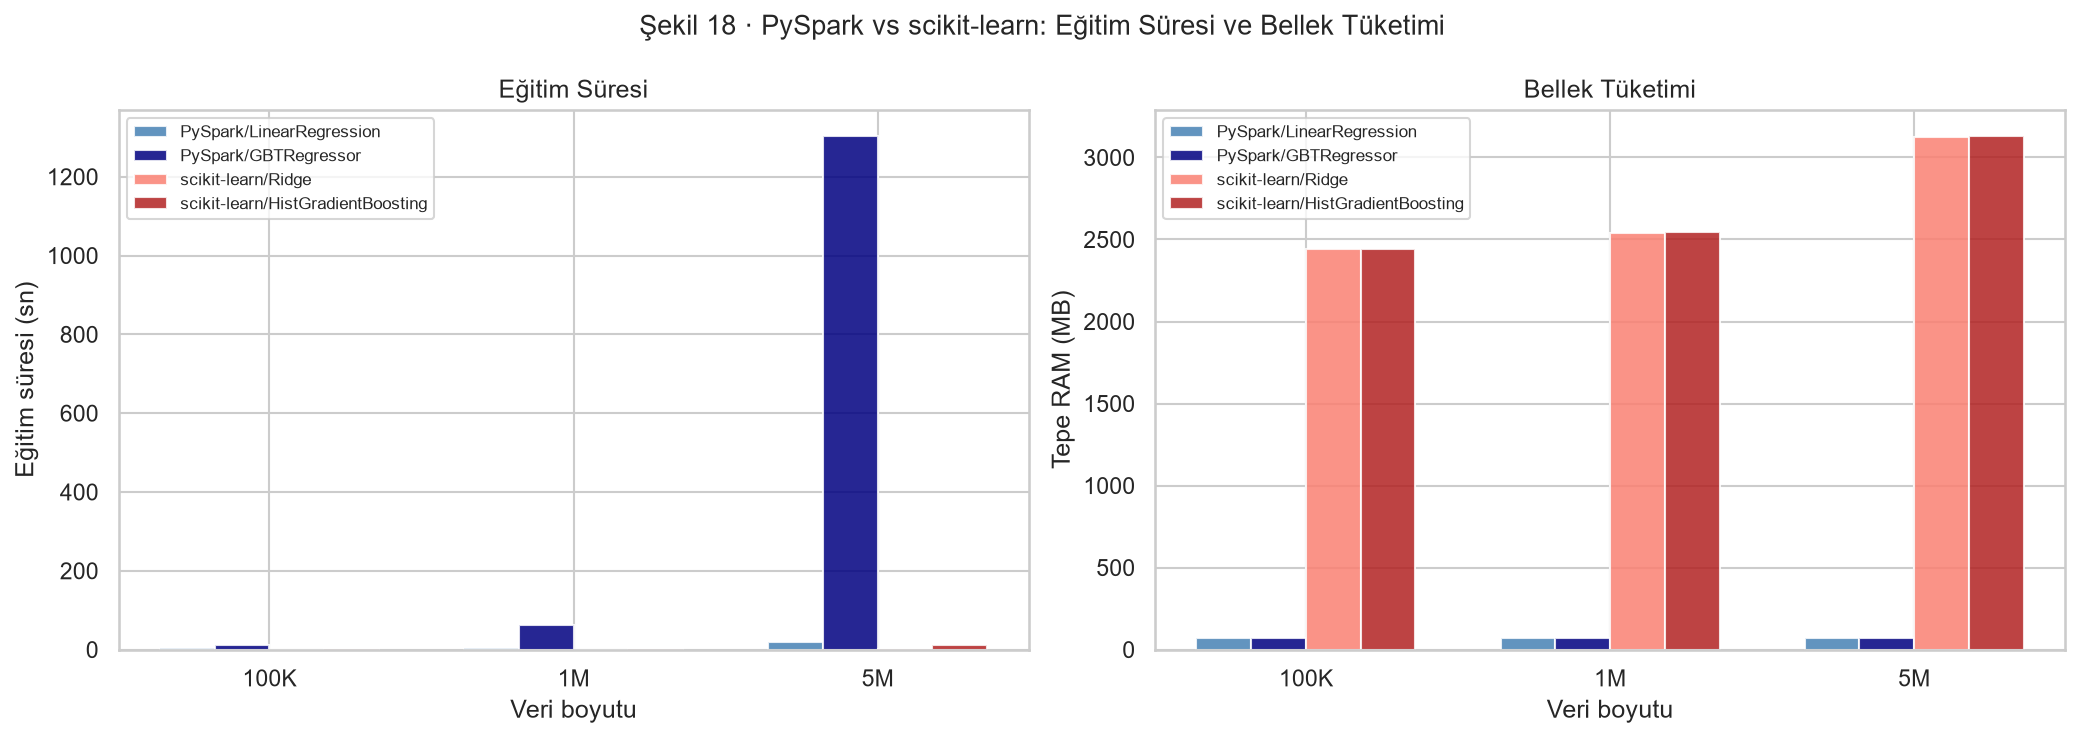

↑ 18_s4_scalability.png


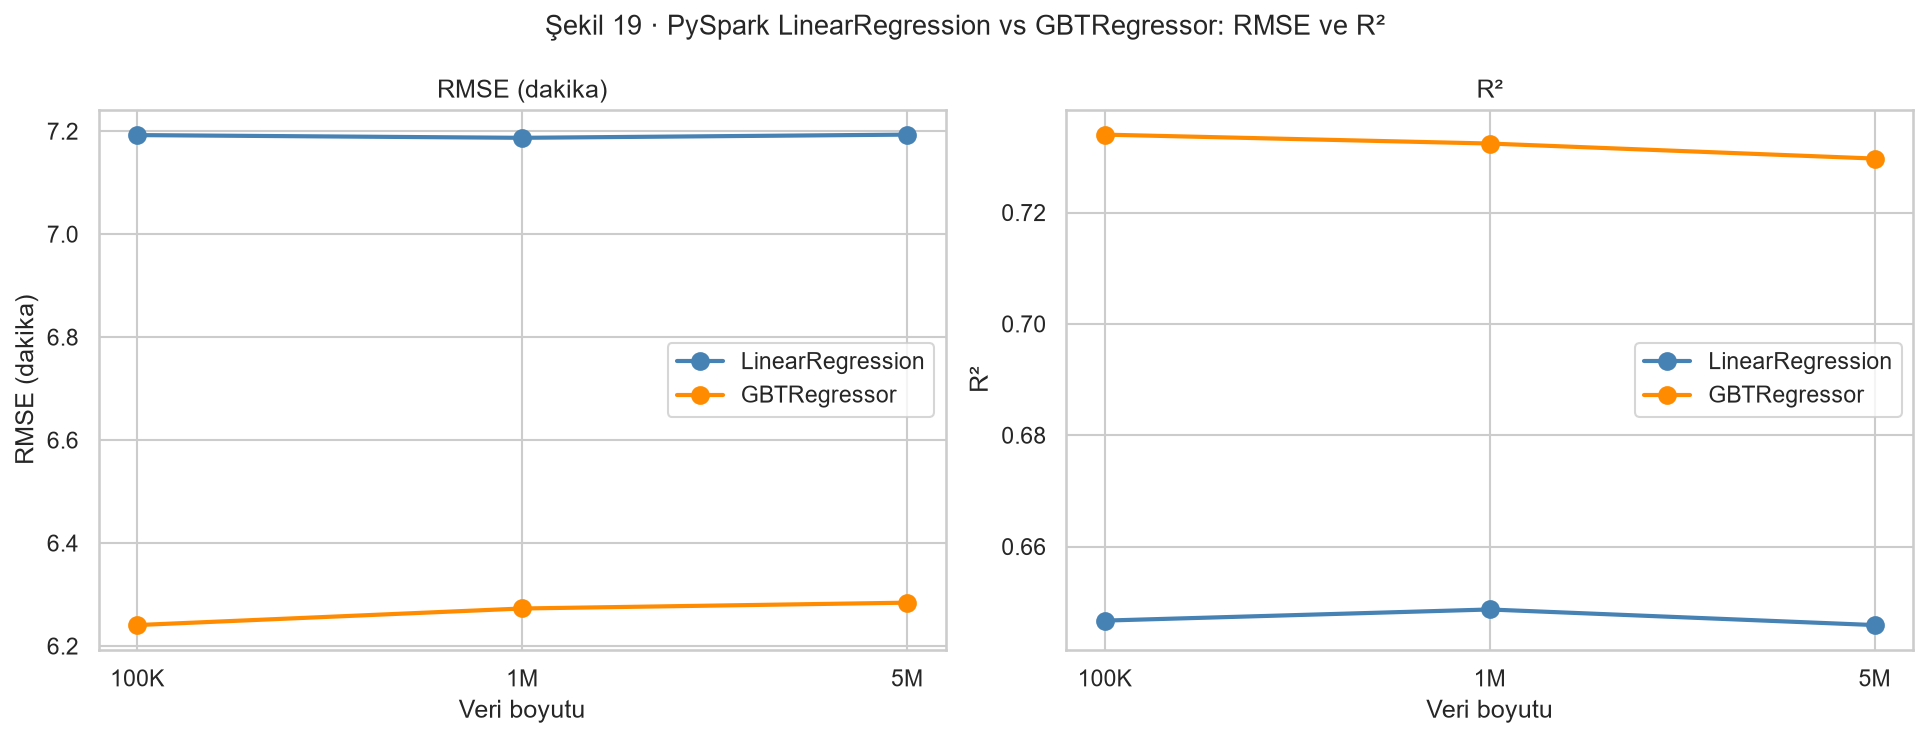

↑ 19_s4_model_comparison.png


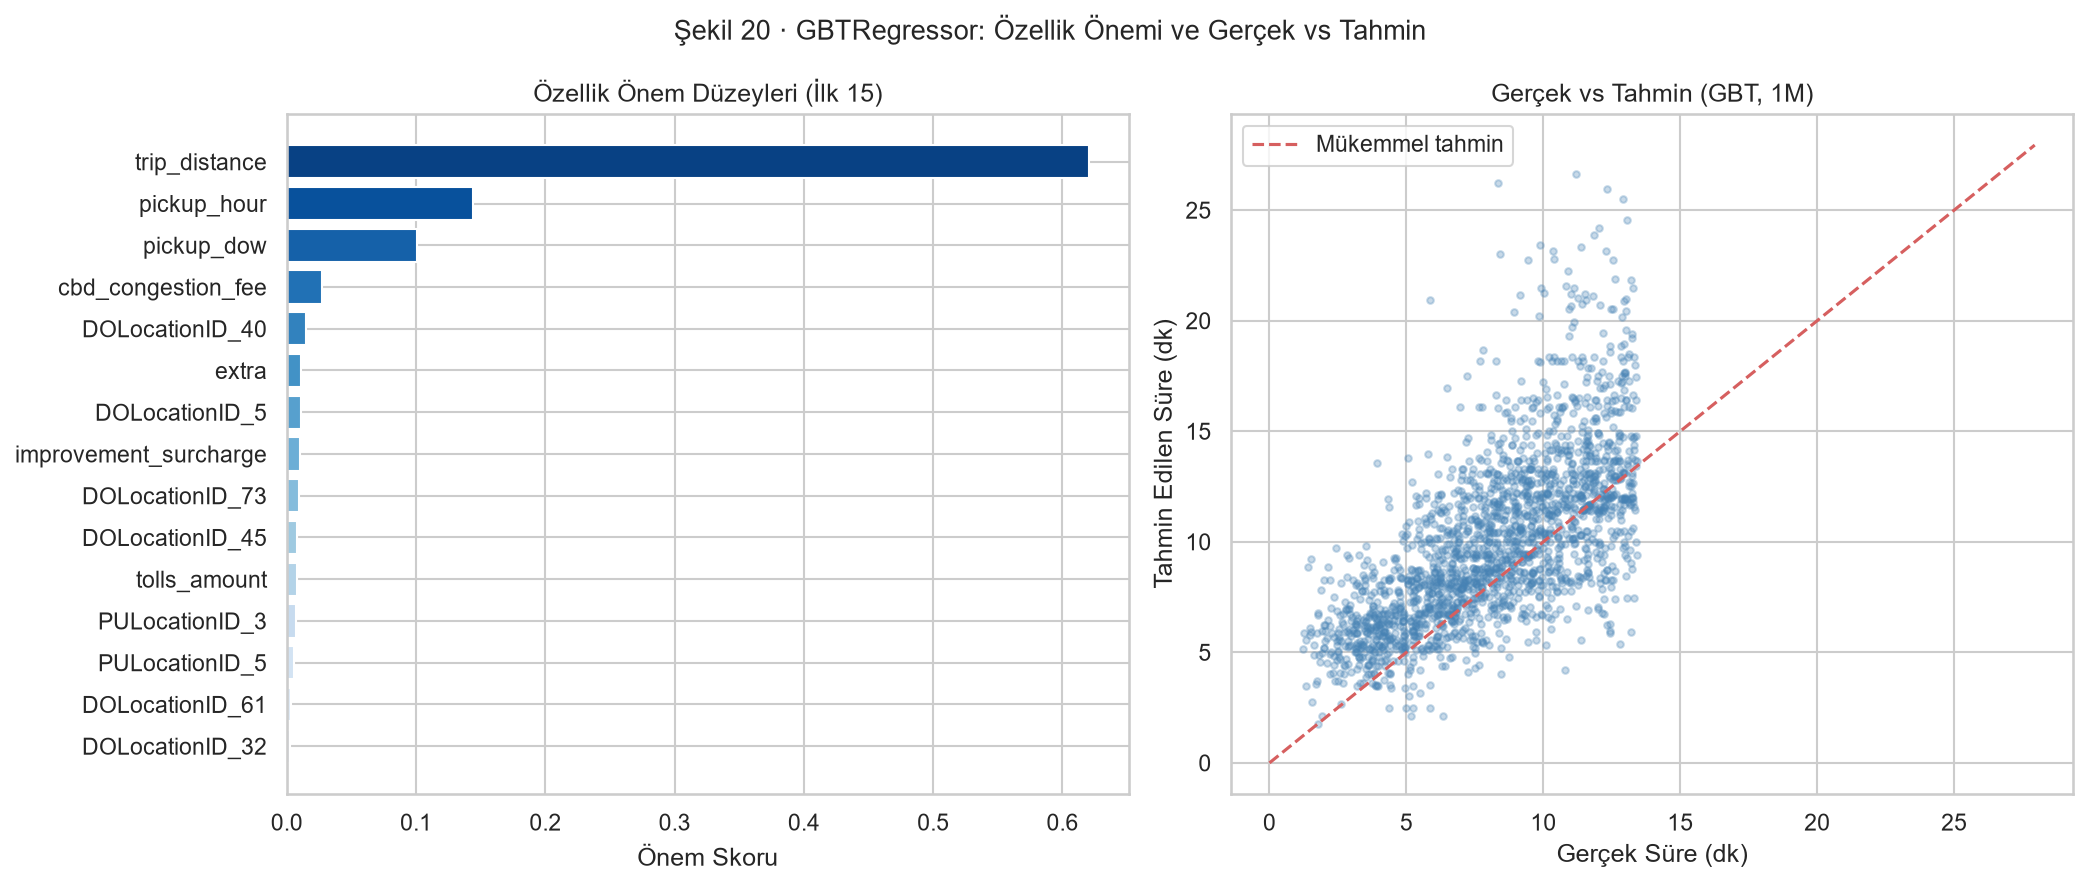

↑ 20_s4_feature_actual_pred.png


In [17]:
# Grafikleri notebook içinde göster
from IPython.display import Image, display
for fig_path in ["18_s4_scalability.png", "19_s4_model_comparison.png", "20_s4_feature_actual_pred.png"]:
    full_path = FIGURES_DIR / fig_path
    if full_path.exists():
        display(Image(filename=str(full_path)))
        print(f"↑ {fig_path}")

## 9. Yorumlar

### Neden GBT > LinearRegression?

Yolculuk süresi–mesafe ilişkisi doğrusal değildir:
- Kısa mesafeli yolculuklar genellikle yoğun Manhattan merkezinde gerçekleşir → birim mesafe başına süre uzar.
- Uzun mesafeli yolculuklar (JFK, havalimanı) sabit tarife veya otoyol kullanımıyla daha öngörülebilir.

GBT, bu eşik etkilerini ağaç bölmeleriyle yakalar; LR ortalamada iyi ama uçlarda sistematik hata yapar.

### Neden R² ~0.73–0.76?

100K'dan 5M'e çıkıldığında bile metriklerin neredeyse sabit kalması (`R²` 0,734 → 0,730), model kapasitesinden değil özellik setindeki bilgi tavanından kaynaklanır. Yolculuk süresi, gerçek zamanlı trafik sinyali, kaza, hava durumu ve özel etkinlik gibi **gözlenemeyen** faktörlerle şekillenir. Bu sınırı aşmak için ek veri kaynakları (trafik API'si, hava durumu) gerekir.

### Klasik Yaklaşımın Bellek Sınırı

`scikit-learn` tek makinede 5M satırı da hızlı biçimde (12,16 sn) tamamlayabilmiştir; ancak tüm veriyi belleğe yüklediği için 100K'da dahi 2,44 GB, 5M'de **3,13 GB** tepe RAM tüketmiştir. PySpark ise Python sürücü belleğini ~72 MB'ta sabit tutar ve 5M GBT sırasında JVM bellek sınırı dolduğunda diske spill ederek çökmeden tamamlar. Veri RAM kapasitesini aştığında (ör. tam 17,2M+ kayıt ve yüksek boyutlu matrisler) klasik yaklaşım yetersiz kalır.

In [18]:
# Oturumu kapat
spark.stop()
print("Spark oturumu kapatıldı ✓")

Spark oturumu kapatıldı ✓
